## Task 4 - Heatwaves
Finding heatwaves in Ås during 2025.  
A heatwave is deffined as five or more consecutive days with temperatures over 27 degrees.


This function `get_max_temperature()` collects data from [The Norwegian meteorological institut](https://www.frost.met.no)

In [36]:
import pandas as pd
import requests
import yaml


def get_max_temperature(
    station_id: str,
    year: int,
) -> pd.DataFrame:
    """Retrieve daily maximum temperatures for a station and year.

    Arguments:
        station_id: Frost station ID.
        year: Year for which to retrive temperatures.

    Returns:
        DataFrame containing dates and daily maximum temperatures.
    """

    with open('met_id.txt', encoding="utf-8") as file:
        client_id = file.readline().strip().split(':')[1]

    # Define endpoint and parameters
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': station_id,
        'elements': 'max(air_temperature P1D)',
        'referencetime': f"{year}-01-01/{year + 1}-01-01",
        'timeoffsets': 'default',
        'levels': 'default',
        }

    # Issue an HTTP GET request
    response = requests.get(
        endpoint,
        params=parameters,
        auth=(client_id, ''),
        timeout=30,
        )
    # timeout=30 sets a 30-second timeout to stop the request if it tekes too long.

    # Extract JSON data
    response_data = response.json()

    # Check if the request worked, print out any errors
    if response.status_code == 200:
        # Convert the observations to DataFrame
        observations = pd.json_normalize(
            response_data['data'],
            record_path="observations",
            meta=['referenceTime', 'sourceId'],
        )

        temperature_df = observations[
            ['referenceTime', 'value']
        ].copy()

        temperature_df = temperature_df.rename(
            columns={
                "referenceTime": "date",
                "value": "temperature",
            }
        )

        # Convert dates to datetime format
        temperature_df['date'] = pd.to_datetime(
            temperature_df['date']
        )
        # Convert temperature to numeric values
        temperature_df['temperature'] = pd.to_numeric(
            temperature_df['temperature']
        )

        return temperature_df

    else:
        raise RuntimeError(
            f"Frost request failed with status code"
            f"{response.status_code}: {response.text}"
        )

This function `find_heatwaves()`analyses the data to find the heatwaves.  
The function itterates through the data and if the temperature is over 27 degrees the day is added to the vaiable hot_days. When it meets a day below 27 degrees it will end the counting, if it was five consecutive it is added as a heatwave. The function also works if a heatwave shoud come at the end of a year (or the chosen timeperiod). examle if a heatwave is ongoing during newyears it will use the last day of the timeperiod as enddate for the analysis. 

In [37]:
# Heatwave deffined as 5 consecutive days with T_max>=27*C
def find_heatwaves(df: pd.DataFrame) -> list[tuple[str, str]]:
    """Find heatwaves, defined as five or more consecutive days,
    with temperatures of 27 degrees or more.

    Arguments:
        df: DataFrame containing 'date' and 'temperature' columns.

    Returns:
        A list of tuples containing the start and end dates of each heatwave.
    """

    hot_days = df['temperature'] >= 27

    # Variables for the colected data
    heatwaves = []      # List that will collect start/end dates for heatwaves
    start_date = None   # We don't know when a heatwave wil start, so we use None.
    # None is a Python value that means we don't have a value yet.
    # No hot period has beed registerd at the beginning

    consecutive_days = 0    # Increases by one when a hot day is registered.

    for index, is_hot in enumerate(hot_days):
        # index - position of the day in the DataFrame
        # is_hot - gives a True/False statement about whether the day is hot
        if is_hot:
            if consecutive_days == 0:
                start_date = df.iloc[index]['date']

            consecutive_days += 1

        # Now check whether the period lasted >=5 days
        # If yes, save te heatwave
        # Then reset the counter so we can start again
        else:
            if consecutive_days >= 5:
                end_date = df.iloc[index - 1]['date']   # iloc retrives the row at the specified position

                # strftime formats the date
                heatwaves.append(
                    (
                        start_date.strftime("%Y-%m-%d"),
                        end_date.strftime("%Y-%m-%d"),
                    )
                )

            consecutive_days = 0
            start_date = None

    # Handle a heatwave at the end of the year that does not end with a temperature below 27 degrees
    if consecutive_days >= 5:
        end_date = df.iloc[-1]['date']  # iloc[-1] retrives the last row in the dataset
        heatwaves.append(
            (
                start_date.strftime("%Y-%m-%d"),
                end_date.strftime("%Y-%m-%d"),
            )
        )

    return heatwaves


This `summarize_heatwaves()` function formattes the collected heatwaves and returns a summary

In [38]:
def summarize_heatwaves(
    heatwaves: list[tuple[str, str]],
    station_id: str,
    station_name: str,
    year: int,
) -> dict:
    """Create a summary of heatwaves for a station and year.

    Arguments:
        heatwaves: List of start and end dates for each heatwave.
        station_id: ID fo the weather station.
        station_name: Name of the weather station.
        year: Year for which heatwaves are summarized.

    Returns:
        A dictionary containing the heatwave dates, station ID,
        station name, and year.
    """
    # Formatting the dates from tuples to strings, in new list
    formatted_dates = [f"{start_date} - {end_date}" for start_date, end_date in heatwaves]

    summary = {
        "dates": formatted_dates,
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }

    return summary

This function `write_heatwaves_to_yaml()` takes the formatted summary and writes it over to a YAML fil formatted as the example file. 

In [39]:
def write_heatwaves_to_yaml(summary: dict, filename: str) -> None:
    """Write a heatwave summary to a YAML file.

    Arguments:
        summary: Dictionary containing the heatwave summary.
        filename: Name of the YAML file to write.

    Returns:
        None.
    """
    with open(filename, "w", encoding="utf-8") as file:
        # encoding=utf-8, sørger for at tekst inkludert Å blir håndtert riktig
        # as file - navn så vi kan skrive fil
        yaml.dump(summary, file, allow_unicode=True, sort_keys=False)
        # allow_unicode=True - tillater bokstaver som Å kan skrives i filen
        # sort_keys=False gjør at nøkler beholdes i samme rekkefølge som i dict

Here we call the functions

In [40]:
# Calling the function - here we put in the station id and year, so it works for different stations
temperature_df = get_max_temperature(
    station_id="SN17850",
    year=2025,
)

# Finding heatwaves form the datasett
heatwaves = find_heatwaves(temperature_df)

# Runn with formatted dates
summary = summarize_heatwaves(
    heatwaves=heatwaves,
    station_id="SN17850",
    station_name="Ås",
    year=2025,
)

# Kall funksjonen og lag filnavn
write_heatwaves_to_yaml(summary=summary, filename="heatwave_summary.yml")

## Task 5 - Moving average temperature
Find the moving average 7-day temperature and compare it to the daily mean temperature we found in task 1. Plott the moving average together with the daily mean temperature

Collecting data from Frost

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import requests

with open('met_id.txt') as f:
    client_id = f'{f.readline().strip().split(':')[1]}'

# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2026-01-01',
    'timeoffsets': 'default',
    'levels': 'default',
    }
# må sette sluttdato til 26-01-01 fordi de bruker åpne intervaller og dermed ikke inkluderer siste dato

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))
# Extract JSON data
data = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = data['data']
    print('Data retrieved from frost.met.no!')
else:
    print(f'Error! Returned status code {r.status_code}')
    print(f'Message: {data['error']['message']}')
    print(f'Reason: {data['error']['reason']}')

# This will return a Dataframe with all of the observations in a table format
# Convert the observations to a DataFrame
df = pd.json_normalize(
    data,
    record_path='observations',
    meta=['referenceTime', 'sourceId'],
)

Data retrieved from frost.met.no!


making dataframe, with only date and temperature. 

In [42]:
# Lager en ny dataframe for dato og temperatur
temperature_df = df[['referenceTime', 'value']].copy()

temperature_df = temperature_df.rename(
    columns={
        'referenceTime': 'date',
        'value': 'temperature',
    }
)

temperature_df['date'] = pd.to_datetime(
    temperature_df['date']
)

temperature_df['temperature'] = pd.to_numeric(
    temperature_df['temperature']
)


This function `temperature_summary()` summarises the data in the dataframe above, showing mean, median, min and max temperature. 

In [43]:
def temperature_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Calculate summary statistics for the temperature data.

    Arguments:
    df: DataFrame containing a 'temperature' column.

    Returns:
    DataFrame containing the mean, median, minimum and maximum temperature."""
    summary = pd.DataFrame({
        'temperature': [
            df['temperature'].mean(),
            df['temperature'].median(),
            df['temperature'].min(),
            df['temperature'].max(),
        ]
    }, index=['mean', 'median', 'min', 'max'])

    return summary


summary = temperature_summary(temperature_df)

print(summary)

        temperature
mean       7.869041
median     8.300000
min      -15.500000
max       23.700000


This function `moving_average_temperature()` calculates the moving average 7-day temperature.

In [44]:
def moving_average_temperature(df: pd.DataFrame) -> pd.Series:
    """Calculate the 7-day moving average of daily temperatures.

    Arguments:
        df: DataFrame containing a temperature column with daily
            mean temperatures.

    Returns:
        Series containing the 7-day moving average. The first six
            values are NaN because there are not enough ovservations.
    """
    moving_average = df['temperature'].rolling(window=7).mean()
# series - returns a pandas-series with averagevalues
# rolling(window=7) - collects 7 days at a time as a "window"

    return moving_average


moving_average = moving_average_temperature(temperature_df)

Here we plott the daily average temperatures as pints and the moving 7-day average temperature as a line in the same plott.

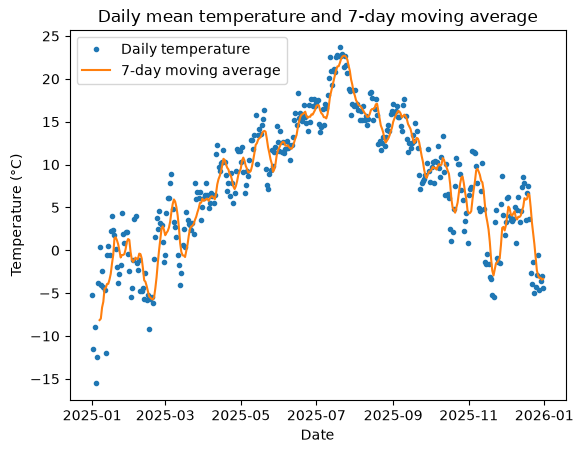

In [45]:
# lager plot
# average temperature - points
x = temperature_df['date']
y = temperature_df['temperature']

plt.plot(x, y, '.', label='Daily temperature')

# Plott for moving average as a line
plt.plot(x, moving_average, label='7-day moving average')


plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.title('Daily mean temperature and 7-day moving average')
plt.legend()
plt.show()
